# Model 2 - Speaker VAE
Run the setup cell first, then **Run all**. 50 epochs, about 15 minutes on a T4.
Needs `ae_best.pt` from notebook 01 and the cache from notebook 00.

In [1]:
!pip install -q librosa soundfile num2words scikit-learn


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\INTEL\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

GPU: NVIDIA GeForce RTX 4070


[vae] starting fresh
[vae] epoch 1/80  train=1.3482  recon=0.0280  kl=23.4527  spk_ce=1.3191  val=0.3801  val_spk_acc=0.8942  (14s)  * best
[vae] epoch 2/80  train=0.4339  recon=0.0187  kl=31.0198  spk_ce=0.4121  val=0.2259  val_spk_acc=0.9397  (14s)  * best
[vae] epoch 3/80  train=0.3354  recon=0.0170  kl=29.2672  spk_ce=0.3139  val=0.2187  val_spk_acc=0.9402  (14s)  * best
[vae] epoch 4/80  train=0.2902  recon=0.0161  kl=26.1661  spk_ce=0.2689  val=0.1882  val_spk_acc=0.9494  (14s)  * best
[vae] epoch 5/80  train=0.2574  recon=0.0156  kl=24.0697  spk_ce=0.2358  val=0.1568  val_spk_acc=0.9601  (14s)  * best
[vae] epoch 6/80  train=0.2320  recon=0.0151  kl=22.3732  spk_ce=0.2101  val=0.1513  val_spk_acc=0.9620  (14s)  * best
[vae] epoch 7/80  train=0.2194  recon=0.0148  kl=20.5244  spk_ce=0.1974  val=0.1834  val_spk_acc=0.9531  (14s)
[vae] epoch 8/80  train=0.2022  recon=0.0145  kl=18.7614  spk_ce=0.1802  val=0.1471  val_spk_acc=0.9609  (14s)  * best
[vae] epoch 9/80  train=0.1948  rec

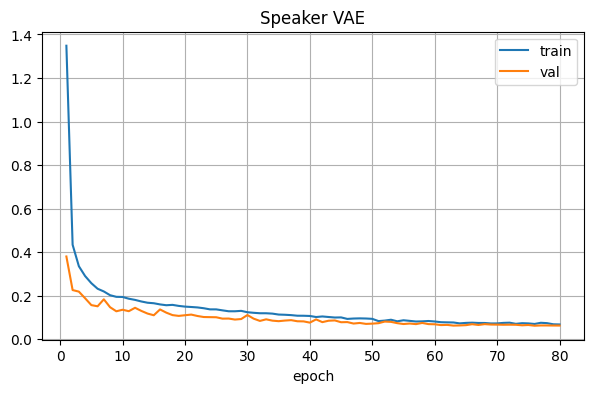

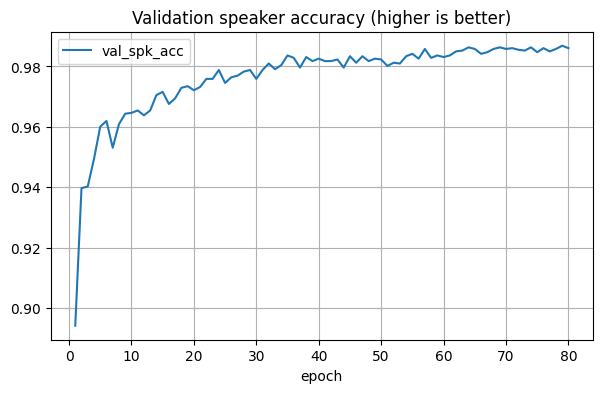

In [4]:
from vc_lib import train_vae
from vc_lib.common import plot_history

hist = train_vae.train(ROOT, epochs=80, batch_size=32, lr=1e-3)
plot_history(hist, ['train', 'val'], 'Speaker VAE')
plot_history(hist, ['val_spk_acc'], 'Validation speaker accuracy (higher is better)')

## Embedding map
Left: each colour is one speaker (colours repeat when there are more than 20 speakers). Right: training voices vs the 4 unseen voices. Unseen voices sitting inside the grey clusters = good zero-shot.

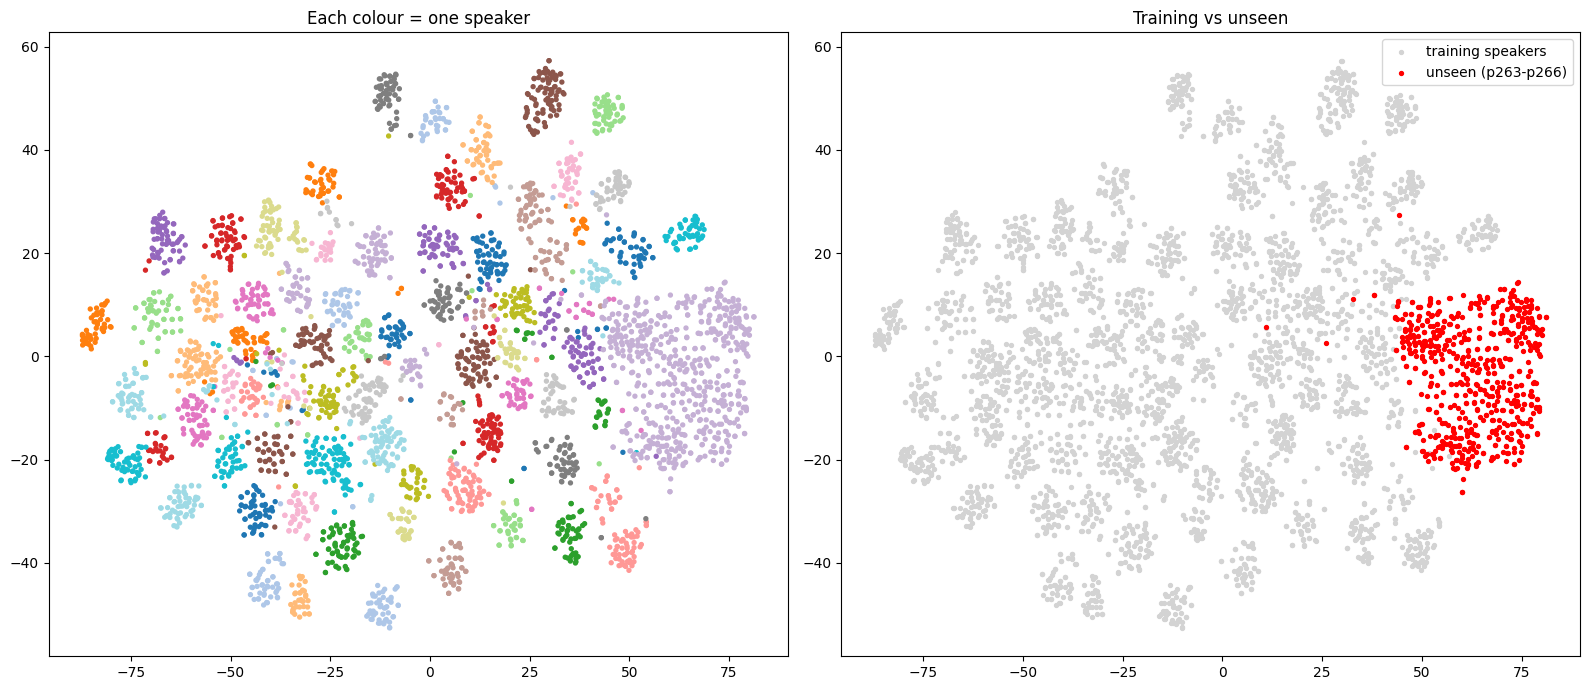

In [5]:
import torch, numpy as np, matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from vc_lib.common import paths, load_cache, tload, load_meta
p = paths(ROOT); C = load_cache(p); mus = tload(p['vae_mu']); meta = load_meta(p)
rows = torch.cat([C['idx']['val'], C['idx']['holdout'][:600]])
names = [C['spks'][i] for i in rows.tolist()]
hold = set(meta['holdout'])
is_hold = np.array([n in hold for n in names])
z = TSNE(2, random_state=0, perplexity=30).fit_transform(mus[rows].numpy())
uniq = sorted(set(names))
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].scatter(z[:, 0], z[:, 1], c=[uniq.index(n) for n in names], cmap='tab20', s=8); ax[0].set_title('Each colour = one speaker')
ax[1].scatter(z[~is_hold, 0], z[~is_hold, 1], c='lightgray', s=8, label='training speakers')
ax[1].scatter(z[is_hold, 0], z[is_hold, 1], c='red', s=8, label='unseen (p263-p266)')
ax[1].legend(); ax[1].set_title('Training vs unseen')
plt.tight_layout(); plt.show()